# Submission

Turns the trained model into the Kaggle submission file for the 180 test images.

| step | state |
|---|---|
| Predict all 180 test images, apply post-processing | done |
| Store results in a format-neutral way (instance maps + per-instance table) | done |
| Pre-flight checks, and a comparison against validation | done |
| **Write the submission CSV and verify it pixel-for-pixel** | **done** |
| Upload to Kaggle | yours to do |
| Final deliverables (report, public repository) | see section 7 |

**Model and settings**

* Model: the cosine-decay run, epoch 8 (`unet_resnet34_clahe_bce_tversky_cosine_best.pt`).
* Post-processing: hysteresis thresholding, low 0.4 / high 0.995, minimum area 400 px
  (`F.SUBMISSION_CFG`).
* On the held-out half of validation this scored **PQ 0.3606** and **mean Dice 0.6233**.
  Both are optimistic: epoch 8 was the best of ten epochs on the same validation
  images, and the final epoch, which was not selected, scored PQ 0.3392. Expect the
  leaderboard to land somewhere around 0.30-0.36 PQ. The organisers describe any
  PQ above 0.35 as "of great value", so that is the level to read the number against.
  A score far below 0.30 means something differs between this pipeline and the
  scorer, not that the model is bad.

## 1. Setup

In [1]:
%load_ext autoreload
%autoreload 2

import json
import os
import sys

sys.path.insert(0, os.path.abspath("../src"))

import matplotlib.pyplot as plt
import numpy as np

import filament as F

TAG = F.TAG + "_cosine"                                  # the model used for submission
CKPT = os.path.join(F.CHECKPOINT_DIR, f"{TAG}_best.pt")
print("post-processing:", F.SUBMISSION_CFG)

post-processing: {'low': 0.4, 'high': 0.995, 'min_area': 400}


## 2. Predict the test set

Each image is tiled, run through the network, and the overlapping tile predictions
are averaged. The probability map is then turned into instances with the settings
above. Results are written to `cache/` as one instance map plus one small JSON per
image, so any output format can be produced later without re-running the network.
Existing results are skipped, so re-running this cell is cheap.

`manifest.json` records the SHA-256 of the checkpoint and every setting, so a
result can always be traced back to the exact model that produced it.

In [2]:
model, ck = F.load_model("best", tag=TAG)
MODEL_KEY = f"{ck['epoch']}_{ck['best_val_iou']:.4f}"
RESULTS = F.predict_test_instances(model, MODEL_KEY, checkpoint_path=CKPT)   # ~2 min first time

with open(os.path.join(RESULTS, "manifest.json")) as f:
    manifest = json.load(f)
print(json.dumps(manifest, indent=2))

loaded unet_resnet34_clahe_bce_tversky_cosine_best.pt: epoch 8, best val IoU 0.4508
180 test images in c:\Users\Ibaan Ibrahim\Documents\Coding\Hackathon\Solar Filament Segmentation Challenge 2026\cache\test_8_0.4508_high0.995_low0.4_min_area400 (0 computed, 180 cached)
{
  "model_key": "8_0.4508",
  "cfg": {
    "low": 0.4,
    "high": 0.995,
    "min_area": 400
  },
  "n_images": 180,
  "clahe": [
    1.0,
    [
      16,
      16
    ]
  ],
  "tile": [
    512,
    384
  ],
  "checkpoint": "unet_resnet34_clahe_bce_tversky_cosine_best.pt",
  "checkpoint_sha256": "179939b0d1939386b1fbc955d15674af02cc2acce483355cc928fa3eb99f0865"
}


## 3. Pre-flight checks

Mechanical correctness of what was produced, independent of how good it is: every
test image has a result, the maps have the right shape, instance ids are
contiguous, and nothing is smaller than the minimum area.

In [3]:
names = F.list_test_images()
problems = []
total_instances = 0
for nm in names:
    inst, meta = F.load_test_instances(RESULTS, nm)
    ids = np.unique(inst[inst > 0])
    total_instances += len(ids)
    if inst.shape != (2048, 2048):
        problems.append((nm, "shape", inst.shape))
    if len(ids) != len(meta["instances"]):
        problems.append((nm, "table and map disagree", (len(ids), len(meta["instances"]))))
    if len(ids) and not np.array_equal(ids, np.arange(1, len(ids) + 1)):
        problems.append((nm, "instance ids are not 1..n", ids[:5]))
    for i in meta["instances"]:
        if i["area"] < F.SUBMISSION_CFG["min_area"]:
            problems.append((nm, "below min_area", i["area"]))

print(f"{len(names)} test images, {total_instances} instances in total")
print(f"{len(problems)} problems")
for p in problems[:10]:
    print("  ", p)
assert not problems
assert len(names) == 180

180 test images, 1442 instances in total
0 problems


## 4. Do the test predictions look like the validation predictions?

The same model and settings were scored on validation, so the test predictions
should look statistically similar. A large difference would point to a pipeline
problem (different preprocessing, a different image scale) rather than a different
sky. The test images also match the training images in size (2048 x 2048),
greyscale mode, mean intensity (83.9 against 83.3) and naming convention, and
none of the test files appear in the training set.

In [4]:
ctx = F.setup(verbose=False)
val_probs = F.load_val_probs(ctx, MODEL_KEY)


def summarise(per_image):
    n = np.array([p[0] for p in per_image])
    fg = np.array([p[1] for p in per_image])
    areas = np.concatenate([p[2] for p in per_image if len(p[2])])
    return n, fg, areas


test_rows = []
for nm in names:
    inst, meta = F.load_test_instances(RESULTS, nm)
    test_rows.append((len(meta["instances"]), (inst > 0).mean(),
                      np.array([i["area"] for i in meta["instances"]])))

val_rows = []
for iid in ctx.val_ids:
    inst, n = F.segment_instances(val_probs[iid].astype(np.float32), **F.SUBMISSION_CFG)
    val_rows.append((n, (inst > 0).mean(), np.bincount(inst.ravel())[1:] if n else np.array([])))

tn, tfg, ta = summarise(test_rows)
vn, vfg, va = summarise(val_rows)
print(f"{'':32} {'test (180)':>12} {'val (161)':>12}")
print(f"{'instances per image, mean':32} {tn.mean():12.2f} {vn.mean():12.2f}")
print(f"{'instances per image, median':32} {np.median(tn):12.1f} {np.median(vn):12.1f}")
print(f"{'instances per image, max':32} {tn.max():12d} {vn.max():12d}")
print(f"{'images with no instance':32} {100 * (tn == 0).mean():11.1f}% {100 * (vn == 0).mean():11.1f}%")
print(f"{'foreground fraction, mean':32} {100 * tfg.mean():11.3f}% {100 * vfg.mean():11.3f}%")
print(f"{'instance area, median (px)':32} {np.median(ta):12.0f} {np.median(va):12.0f}")
print(f"{'instance area, 90th pct (px)':32} {np.percentile(ta, 90):12.0f} {np.percentile(va, 90):12.0f}")

                                   test (180)    val (161)
instances per image, mean                8.01         7.35
instances per image, median               8.0          7.0
instances per image, max                   21           19
images with no instance                  1.7%         6.8%
foreground fraction, mean              0.389%       0.363%
instance area, median (px)               1390         1415
instance area, 90th pct (px)             4196         4323


They agree closely. The one visible difference is the share of images with no
detection (about 2% on test against 7% on validation) - three images against
eleven. That is plausible if the test period was more active, and nothing else
differs, but it is the first thing to look at if the leaderboard score disappoints.

Below: the two test images with the most detections, the two with the fewest, and
two at random.

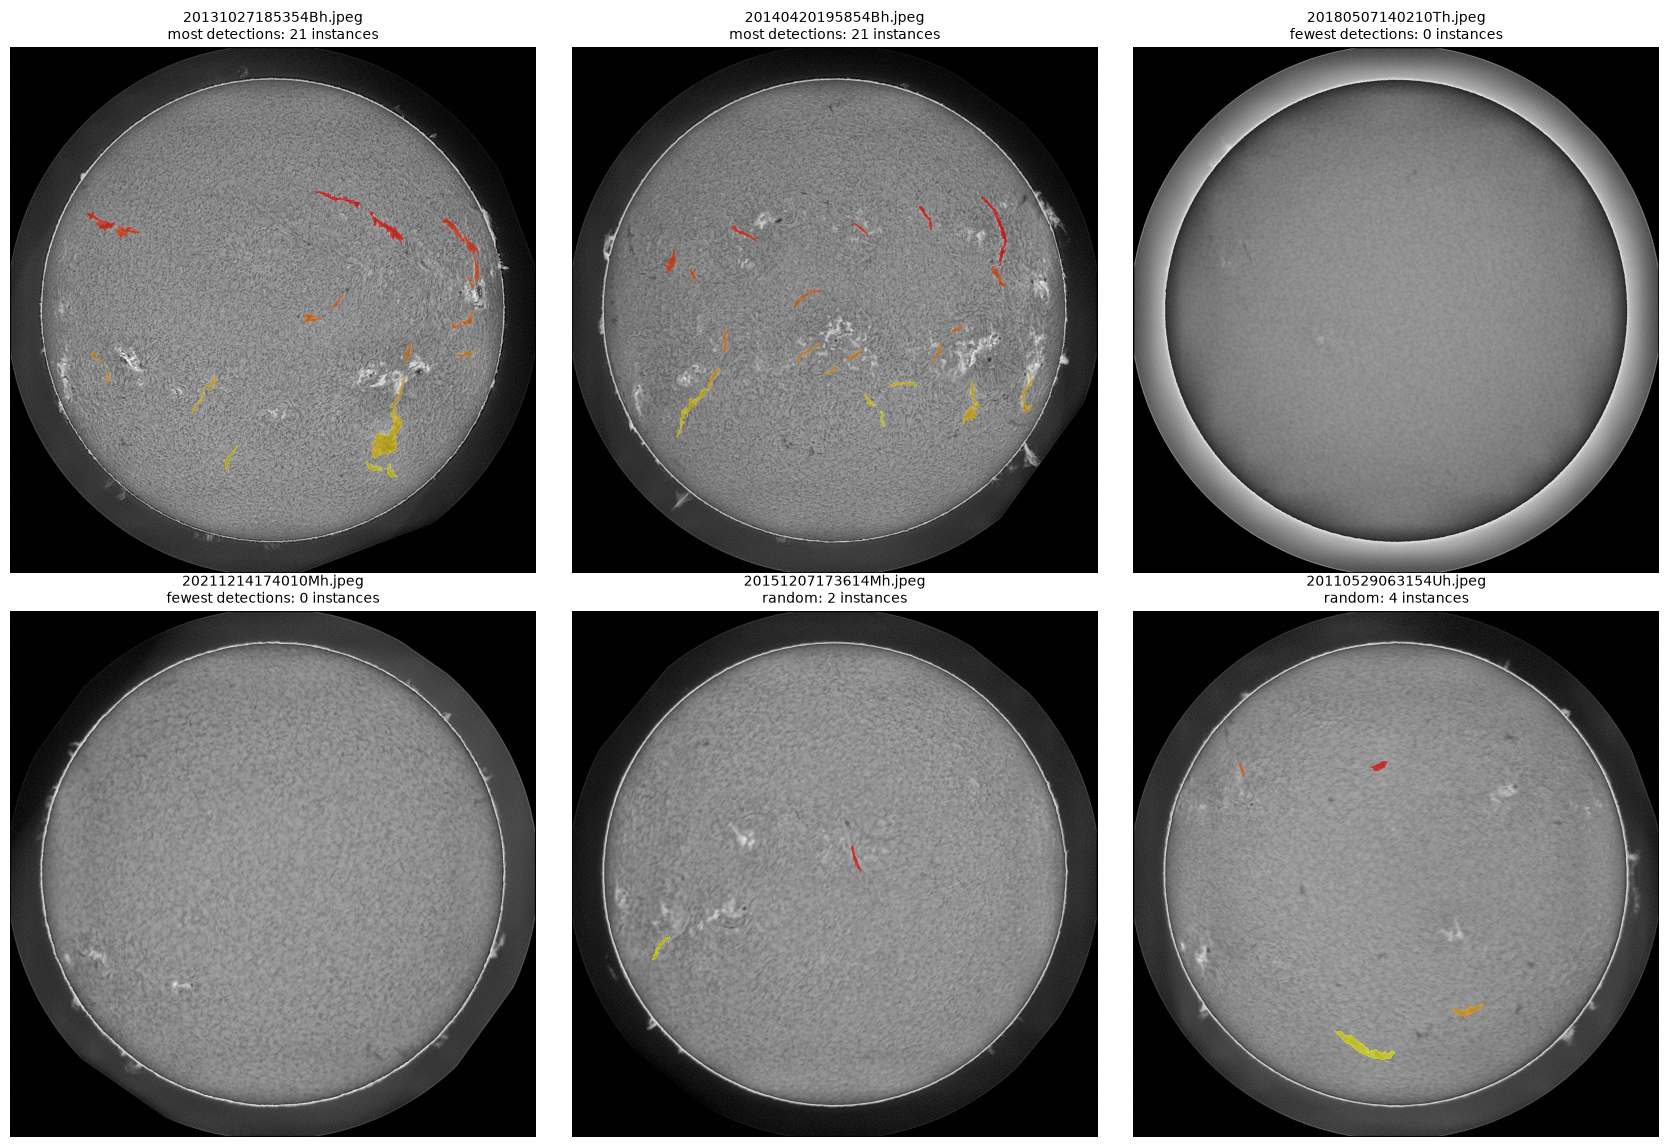

In [5]:
counts = np.array([len(F.load_test_instances(RESULTS, nm)[1]["instances"]) for nm in names])
order = np.argsort(counts)
rng = np.random.RandomState(0)
picks = list(order[-2:][::-1]) + list(order[:2]) + list(rng.choice(len(names), 2, replace=False))
labels = ["most detections"] * 2 + ["fewest detections"] * 2 + ["random"] * 2

fig, axes = plt.subplots(2, 3, figsize=(17, 11.5))
for ax, k, lab in zip(axes.ravel(), picks, labels):
    nm = names[k]
    img = F.read_image_path(os.path.join(F.TEST_IMAGES, nm))
    inst, meta = F.load_test_instances(RESULTS, nm)
    ax.imshow(img, cmap="gray")
    ax.imshow(np.ma.masked_where(inst == 0, inst), cmap="autumn", alpha=0.55,
              interpolation="nearest")
    ax.set_title(f"{nm}\n{lab}: {len(meta['instances'])} instances", fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Dice and PQ: does tuning for one hurt the other?

The rubric scores **both** Panoptic Quality and mean Dice, and the post-processing
was tuned on PQ only. If keeping fewer, more confident blobs cost Dice, there would
be a trade-off to settle. There is not: the chosen setting is best on both.
Dice moves very little between settings (it is dominated by mask quality, not by
which blobs are kept), so one submission serves both metrics.

Dice here is the per-image Dice of all filament pixels merged, averaged over images.
The competition names `torchmetrics`' `DiceScore`, whose exact averaging is not
documented on the page, so read these as close rather than identical.

In [6]:
gt_cache = {i: F.gt_instances(ctx.images_by_id, ctx.anns_by_image_id, i, F.GT_MIN_AREA)[0]
                 .astype(np.int16) for i in ctx.val_ids}
A, B = F.split_val_by_file(ctx)

configs = {
    "no filtering        (0.5 / - / 1 px)":       dict(low=0.5, min_area=1),
    "default             (0.5 / - / 20 px)":      dict(low=0.5, min_area=20),
    "min-area only       (0.3 / - / 800 px)":     dict(low=0.3, min_area=800),
    "hysteresis, chosen  (0.4 / 0.995 / 400 px)": dict(low=0.4, high=0.995, min_area=400),
}
print(f"{'':44} {'Dice B':>8} {'PQ B':>8}    (B = held-out half)")
for name, cfg in configs.items():
    dice_b, _ = F.dice_from_probs(B, val_probs, ctx, gt_cache, **cfg)
    pq_b = F.pq_from_probs(B, val_probs, ctx, gt_cache, **cfg)["pq"]
    print(f"{name:44} {dice_b:8.4f} {pq_b:8.4f}")

                                               Dice B     PQ B    (B = held-out half)
no filtering        (0.5 / - / 1 px)           0.6174   0.2751
default             (0.5 / - / 20 px)          0.6174   0.2968
min-area only       (0.3 / - / 800 px)         0.6144   0.3575
hysteresis, chosen  (0.4 / 0.995 / 400 px)     0.6233   0.3606


## 6. Writing the submission file

The competition asks for **one CSV for the whole test set, one row per predicted
filament**:

| column | content |
|---|---|
| `filament_id` | the image name without its extension, then `_1`, `_2`, ... e.g. `20150125172714Mh_2`. Any tail works as long as ids are unique and the image part is unchanged. |
| `segmentation_rle` | the COCO run-length **counts** string for that filament's mask. The size is fixed at 2048 x 2048 and is not stored. **No quotation marks.** |

Predicted and ground-truth filaments are matched by overlap, not by index, so the
number of rows per image does not have to equal the number of true filaments. No
class label is needed: the scoring is on segmentation masks only, so the
class-agnostic model is fine.

An image with no detections gets no rows. Adding a dummy mask would turn a missed
filament into a missed filament plus a false positive, which scores worse. The
organisers say messages about edge cases are shown after an upload, so if empty
images are flagged, that is where it will appear.

In [7]:
CFG_TAG = "_".join(f"{k}{v}" for k, v in sorted(F.SUBMISSION_CFG.items()))
SUBMISSION = os.path.join(F.PROJECT_ROOT, "submissions", f"submission_{MODEL_KEY}_{CFG_TAG}.csv")

info = F.write_submission_csv(RESULTS, SUBMISSION)
with_rows = info["images"] - len(info["images_without_rows"])
print(f"wrote {info['path']}")
print(f"{info['rows']} rows for {with_rows} of {info['images']} images "
      f"({os.path.getsize(SUBMISSION) / 1e3:.0f} kB)")
print("images with no detections (no rows):",
      [os.path.splitext(n)[0] for n in info["images_without_rows"]])

print("\nfirst lines, as the scorer will read them:")
with open(SUBMISSION, encoding="utf-8") as f:
    for _ in range(4):
        print("  ", f.readline().rstrip()[:96])

wrote c:\Users\Ibaan Ibrahim\Documents\Coding\Hackathon\Solar Filament Segmentation Challenge 2026\submissions\submission_8_0.4508_high0.995_low0.4_min_area400.csv
1442 rows for 177 of 180 images (366 kB)
images with no detections (no rows): ['20180507140210Th', '20200310113230Ch', '20211214174010Mh']

first lines, as the scorer will read them:
   filament_id,segmentation_rle
   20110120105534Ch_1,b`Vi21oo12O1N1O3N0000O010OHKePN5Vo1LePN135Xo1<000KePNC\o1;5O1001O1O1O1O100001
   20110120105534Ch_2,VjPQ23lo12M3N010O1N1O2O0001N00010000N1101O00J6N2I70O100OL5O1O1O1N3CnNhQNV1Vn1
   20110130110334Ch_1,oZ^P2<co12M5G7L6L3M1000O2N101M5L2N2N3N2N2N1N2L4IUeWn1


### Verify the file against what it was made from

The writer and the checker use different code paths. The checker decodes **every**
row's RLE with `pycocotools` and requires the pixels to equal the stored instance
map exactly, then checks the ids are unique and belong to test images and that no
quote characters crept in. Its tests include deliberately corrupted files (swapped
masks, quoted fields, duplicate ids) to confirm it can fail.

In [8]:
check = F.verify_submission_csv(SUBMISSION, RESULTS)
print(f"rows                       : {check['rows']}")
print(f"images with rows           : {check['images_with_rows']} of 180")
print(f"images without rows        : {check['images_without_rows']}")
print(f"masks differing from source: {check['mismatched_masks']}")
print(f"problems                   : {check['problems'] or 'none'}")
assert not check["problems"] and check["mismatched_masks"] == 0
assert check["rows"] == total_instances

rows                       : 1442
images with rows           : 177 of 180
images without rows        : ['20180507140210Th', '20200310113230Ch', '20211214174010Mh']
masks differing from source: 0
problems                   : none


## 7. Before and after uploading

**Upload** the CSV on the competition's *Submit Predictions* page. Compare the score
with the held-out estimate above. Only **two** submissions count towards the final
leaderboard, so keep them deliberately different (for example this one and a
variant built from the final epoch) rather than two near-copies.

The page says the scoreboard shows the mean Dice for about half of the test images,
while the ranking text describes Panoptic Quality. It is not clear which number the
leaderboard displays, so check which one it is before comparing against the
estimates here (Dice about 0.62, PQ about 0.34-0.36).

**Final deliverables** (the competition closes **15 November 2026, 11:59 pm CDT**),
submitted through the organisers' Google form:

1. A **4-page technical report** on the organisers' Overleaf template, as one PDF.
2. A **public Git repository** with a `requirements.txt` listing every package and
   version, and a **notebook that illustrates the whole pipeline**. The committee
   must be able to reproduce the submitted predictions *without any additional
   file*.

That last requirement has a consequence worth deciding early: the trained weights
are 94 MB each and the workspace rule is never to commit weights. Reproducing the
predictions then means either retraining from scratch (about 10 hours on this GPU,
through `F.train`) or hosting the weights somewhere public and downloading them in
the notebook. The rubric also grades **computational efficiency** and **code
quality**, so the inference time (about 0.7 s per image here) is worth recording.

Improvements that need no new data, in order of expected value:

* **Test-time augmentation** - average predictions over flips. It tends to remove
  exactly the low-confidence blobs that make up most false positives.
* **Predict instances directly** rather than a binary mask plus connected components;
  the rubric also scores one-to-many and many-to-one matches, which is where
  connected components struggle.
* **Pick checkpoints by PQ, or average weights**, instead of tile IoU.